# Practical Class Work - 5
## Title: Fairness Analysis (German Credit Dataset)

In Practice 3 we built a Logistic Regression model that predicts bad credit risk and chose a business threshold of 0.35. Here we check whether this model works equally well for different groups of applicants: by sex and age (sensitive features) and by housing and job (proxy features).

In [26]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import sklearn 

### 1) Data loading and model (same setup as Practice 3)

In [27]:
# there's no column names in the dataset, so we have to specify them 
# from word file german.doc I took the column names and put them in a list

columns = [
    "checking_status", "duration_months", "credit_history", "purpose",
    "credit_amount", "savings", "employment_since", "installment_rate",
    "personal_status_sex", "other_debtors", "residence_since", "property",
    "age", "other_installment_plans", "housing", "existing_credits",
    "job", "people_liable", "telephone", "foreign_worker", "target"
]

In [28]:
df = pd.read_csv("../pr3/dataset/german.data", sep=r"\s+", header=None, names=columns)

In [29]:
df["target"] = df["target"].map({1: 0, 2: 1})   # 1 = bad, 0 = good

In [30]:
numeric_features = df.select_dtypes(include="number").columns.drop("target").tolist()
categorical_features = df.select_dtypes(exclude="number").columns.tolist()

In [31]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [32]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])
model.fit(X_train, y_train)

threshold = 0.35
bad_probability = model.predict_proba(X_test)[:, 1]
y_pred = (bad_probability >= threshold).astype(int)

In [33]:
print(confusion_matrix(y_test, y_pred))

[[109  31]
 [ 14  46]]


The confusion matrix matches Practice 3 at threshold 0.35, so this is the same model.

### 2) Sensitive and proxy features

Sensitive features (required):
- **Sex**: the dataset has no separate sex column, so we take it from `personal_status_sex`. A92 and A95 are female; A91, A93 and A94 are male. A95 never appears in the data, so every woman is coded A92 ("female: divorced/separated/married").
- **Age**: split into two groups, under 30 and 30 or older.

Proxy features (they can indirectly reflect age or income):
- **Housing**: rent, own, or for free.
- **Job**: unskilled/unemployed, skilled, highly qualified. A171 (unemployed/non-resident) has only 6 people in the test set, so we merged it with A172 (unskilled resident).

In [34]:
groups = pd.DataFrame(index=X_test.index)

groups["Sex"] = X_test["personal_status_sex"].map({
    "A91": "Male", "A92": "Female", "A93": "Male", "A94": "Male", "A95": "Female"
})
groups["Age group"] = np.where(X_test["age"] < 30, "<30", ">=30")
groups["Housing"] = X_test["housing"].map({
    "A151": "Rent", "A152": "Own", "A153": "For free"
})
groups["Job"] = X_test["job"].map({
    "A171": "Unskilled/unemployed", "A172": "Unskilled/unemployed",
    "A173": "Skilled", "A174": "Highly qualified"
})

groups.head()

,Sex,Age group,Housing,Job
30,Male,>=30,Own,Skilled
128,Male,>=30,Own,Highly qualified
289,Male,>=30,Own,Skilled
216,Male,>=30,Own,Skilled
966,Male,<30,Own,Unskilled/unemployed


### 3) Metrics per group

For each group we compute Accuracy, Recall, Precision and F1 for the bad class, plus two more:
- **FPR (false positive rate)**: the share of good clients the model wrongly rejects. This is the main fairness metric here, because it shows who is refused a loan they would have repaid.
- **Rejection rate**: the share of the whole group the model rejects.

We also show each group's actual bad rate, because a group with more bad clients will naturally be rejected more often.

In [35]:
def group_metrics(y_true, y_hat):
    tn, fp, fn, tp = confusion_matrix(y_true, y_hat, labels=[0, 1]).ravel()
    return {
        "Size": len(y_true),
        "Bad rate": y_true.mean(),                 # actual share of bad clients
        "Accuracy": accuracy_score(y_true, y_hat),
        "Recall": recall_score(y_true, y_hat, zero_division=0),
        "Precision": precision_score(y_true, y_hat, zero_division=0),
        "F1": f1_score(y_true, y_hat, zero_division=0),
        "FPR": fp / (fp + tn) if (fp + tn) > 0 else np.nan,  # good clients wrongly rejected
        "Rejection rate": y_hat.mean(),            # share of the group the model rejects
    }

In [36]:
y_pred_s = pd.Series(y_pred, index=X_test.index)

overall = pd.DataFrame([group_metrics(y_test, y_pred_s)], index=["Overall"])
print(overall.round(3).to_string())

fairness_tables = {}
for feature in groups.columns:
    rows = {}
    for g in groups[feature].unique():
        mask = groups[feature] == g
        rows[g] = group_metrics(y_test[mask], y_pred_s[mask])
    table = pd.DataFrame(rows).T.sort_values("Size", ascending=False)
    table["Size"] = table["Size"].astype(int)
    fairness_tables[feature] = table
    print(f"\n{feature}")
    print(table.round(3).to_string())

         Size  Bad rate  Accuracy  Recall  Precision     F1    FPR  Rejection rate
Overall   200       0.3     0.775   0.767      0.597  0.672  0.221           0.385

Sex
        Size  Bad rate  Accuracy  Recall  Precision     F1    FPR  Rejection rate
Male     139     0.288     0.770   0.725       0.58  0.644  0.212           0.360
Female    61     0.328     0.787   0.850       0.63  0.723  0.244           0.443

Age group
      Size  Bad rate  Accuracy  Recall  Precision     F1    FPR  Rejection rate
>=30   121     0.215     0.802   0.769      0.526  0.625  0.189           0.314
<30     79     0.430     0.734   0.765      0.667  0.712  0.289           0.494

Housing
          Size  Bad rate  Accuracy  Recall  Precision     F1    FPR  Rejection rate
Own        143     0.266     0.776   0.658      0.568  0.610  0.181           0.308
Rent        35     0.371     0.771   1.000      0.619  0.765  0.364           0.600
For free    22     0.409     0.773   0.889      0.667  0.762  0.308    

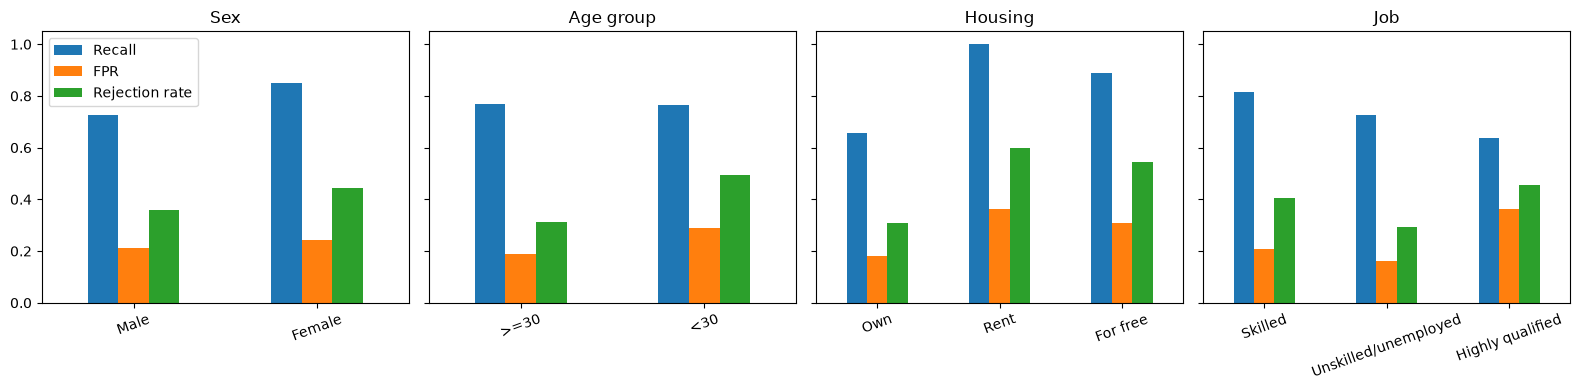

In [37]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, (feature, table) in zip(axes, fairness_tables.items()):
    table[["Recall", "FPR", "Rejection rate"]].plot.bar(ax=ax, rot=20, legend=False)
    ax.set_title(feature)
axes[0].legend()
plt.tight_layout()
plt.show()

**1. Does model performance differ across groups for each feature?**
Yes. Accuracy is similar for most groups (0.73 to 0.80), so it hides the problem. The real gaps are in the false positive rate (good clients wrongly rejected) and the rejection rate. Good applicants under 30 are rejected 29% of the time, compared with 19% for those aged 30 and over. Renters have an FPR of 0.36, while homeowners have 0.18. Between men and women the gap is smaller (0.24 for women vs 0.21 for men). The "Highly qualified" job group has the lowest accuracy (0.64) and the highest FPR (0.36).

**2. Which groups consistently receive worse predictions?**
Young applicants, renters and people living for free. The model rejects about half of each of these groups (49%, 60% and 55%), compared with about 31% of older applicants and homeowners. Many of the people it rejects are actually good clients. Women are also rejected more often than men (44% vs 36%), but that gap is smaller.

**3. Do proxy features reveal additional bias compared to Sex/Age?**
Yes. The Housing gap is larger than the Sex gap and slightly larger than the Age gap. Housing is linked to age: in the full dataset, 30% of applicants under 30 rent, compared with 10% of older applicants. So even if we removed age and sex from the model, it could still treat young people differently through housing.

**4. Why might these differences occur?**
The groups have different bad rates in the data (43% under 30 vs 22% for 30 and over), and the model learns these patterns from past loans, which may themselves be biased. Some groups are small in the test set (22 people living for free, 33 highly qualified, 35 renters), so their metrics are unstable. The sex feature is also mixed with marital status (A92 means "female: divorced/separated/married"), which makes it noisy.

**5. Why is this critical in real-world systems like credit scoring?**
A loan decision affects a real person's access to money for housing, education or a business. If the model wrongly rejects young people and renters more often, the bank is systematically denying credit to people who would repay. In many countries discrimination by sex or age is illegal, and the bank is responsible for its model's decisions. Group metrics should be checked before the model goes into production and monitored after.